## Data analysis fun for LabSmith plots

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
csv_file = "ReactionChamberChip_depressurize_v2_20260227_130318_combined.csv"
df = pd.read_csv(csv_file, sep = ',')

In [ ]:
print(df)

      Time of day  Time (s)  SF06_5: ()  4VM02: V1 state  V2 state  V3 state  \
0             0.0     0.000      -0.167                3         1         1   
1             1.0     0.141      -0.167                3         1         5   
2             1.0     0.250       0.133                3         1         5   
3             1.0     0.359      -0.067                3         1         5   
4             1.0     0.469      -0.067                3         1         5   
...           ...       ...         ...              ...       ...       ...   
1926        214.0    92.454       1.833                3         1         1   
1927        214.0    92.563       1.133                3         1         1   
1928        214.0    92.672       0.933                3         1         1   
1929        215.0    92.797       0.767                3         1         1   
1930        215.0    92.907       1.133                3         1         1   

      V4 state  SPS_1: Volume (ul)  4AM

In [ ]:
time_col = 'Time (s)'
flow_col = 'SF06_5: ()'
pressure_col = next((col for col in df.columns if '15585' in col), None)
valve_col = next((col for col in df.columns if 'V2' in col), None)
syringe_col = next((col for col in df.columns if 'SPS' in col), None)

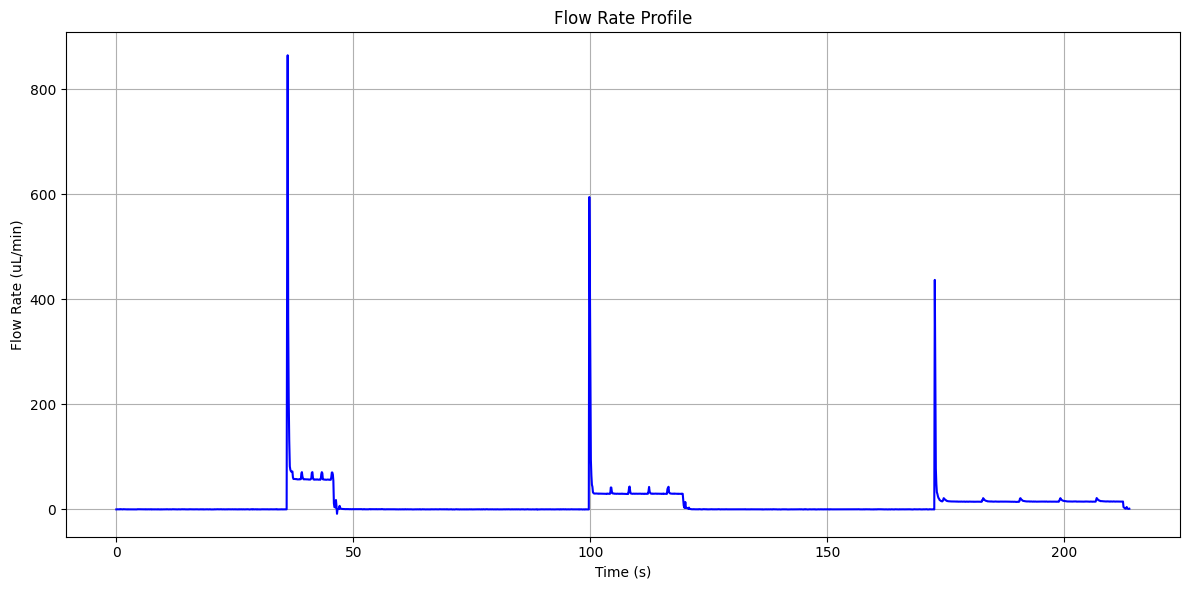

In [ ]:
continuous_time = []
offset = 0
prev_time = 0

for i, t in enumerate(df[time_col]):
    if i > 0 and t < df[time_col].iloc[i - 1]:  # Detected reset
        offset += df[time_col].iloc[i - 1]
    continuous_time.append(t + offset)

df['continuous_time_s'] = continuous_time

# Plot
plt.figure(figsize=(12, 6))
plt.plot(df['continuous_time_s'], df[flow_col], label=flow_col, color = 'blue')
plt.xlabel('Tikkme (s)')
plt.ylabel('Flow Rate (uL/min)')
plt.title('Flow Rate Profile')
plt.grid(True)
plt.tight_layout()
plt.show()

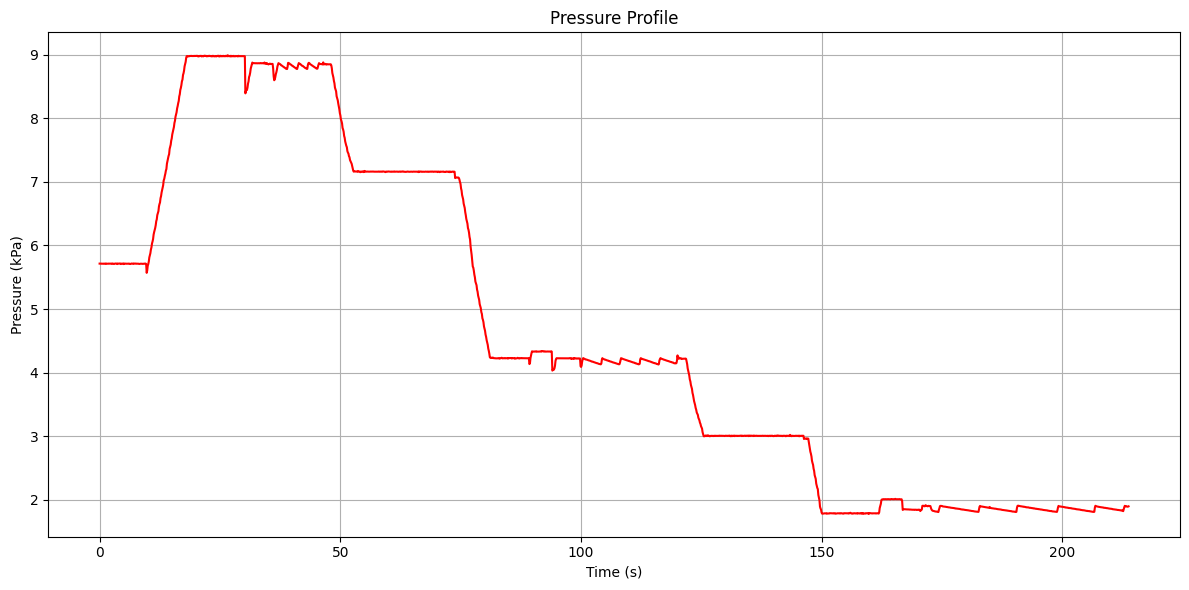

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(df['continuous_time_s'], df[pressure_col], label=pressure_col, color = 'red')
plt.xlabel('Time (s)')
plt.ylabel('Pressure (kPa)')
plt.title('Pressure Profile')
plt.grid(True)
plt.tight_layout()
plt.show()

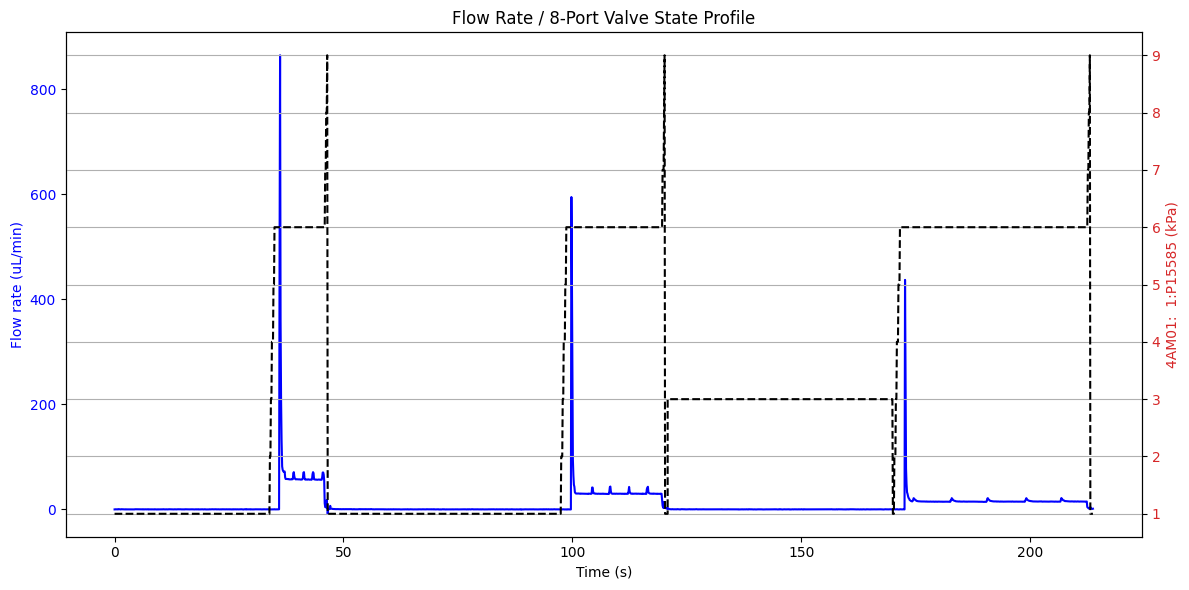

In [ ]:
fig, ax1 = plt.subplots(figsize=(12, 6))

# Primary Y-axis
ax1.plot(df['continuous_time_s'], df[flow_col], color='blue', label=flow_col)
ax1.set_xlabel('Time (s)')
ax1.set_ylabel('Flow rate (uL/min)', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# Secondary Y-axis (if pressure column exists)
if pressure_col:
    ax2 = ax1.twinx()
    ax2.plot(df['continuous_time_s'], df[valve_col], color='black', linestyle = '--', label='AV801 Valve State')
    ax2.set_ylabel(pressure_col, color='tab:red')
    ax2.tick_params(axis='y', labelcolor='tab:red')

# Title and layout
plt.title('Flow Rate / 8-Port Valve State Profile')
fig.tight_layout()
plt.grid(True)
plt.show()

# Flow and pressure profile

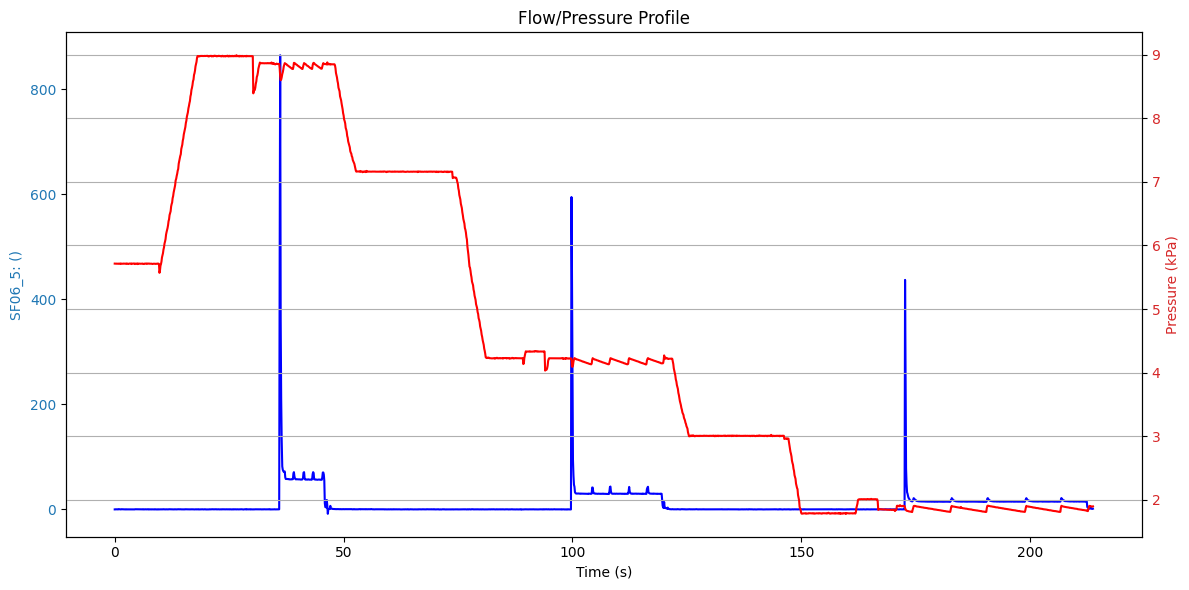

In [ ]:
fig, ax1 = plt.subplots(figsize=(12, 6))

# Primary Y-axis
ax1.plot(df['continuous_time_s'], df[flow_col], color='blue', label=flow_col)
ax1.set_xlabel('Time (s)')
ax1.set_ylabel(flow_col, color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')

# Secondary Y-axis (if pressure column exists)
if pressure_col:
    ax2 = ax1.twinx()
    ax2.plot(df['continuous_time_s'], df[pressure_col], color='red', label=pressure_col)
    ax2.set_ylabel("Pressure (kPa)", color='tab:red')
    ax2.tick_params(axis='y', labelcolor='tab:red')

if syringe_col:
    ax3 = ax1.twinx()
    ax3.plot(df['continuous_time_s'], df[syringe_col], color='black', linestyle = '--', label='Syringe Volume (ul)')
    ax3.set_ylabel(syringe_col, color='black')
    ax3.spines["right"].set_position(("axes", 1.12)); ax3.spines["right"].set_visible(True)
    ax3.tick_params(axis='y', labelcolor='black')

# Title and layout
plt.title('Flow/Pressure Profile')
fig.tight_layout()
plt.grid(True)
plt.show()

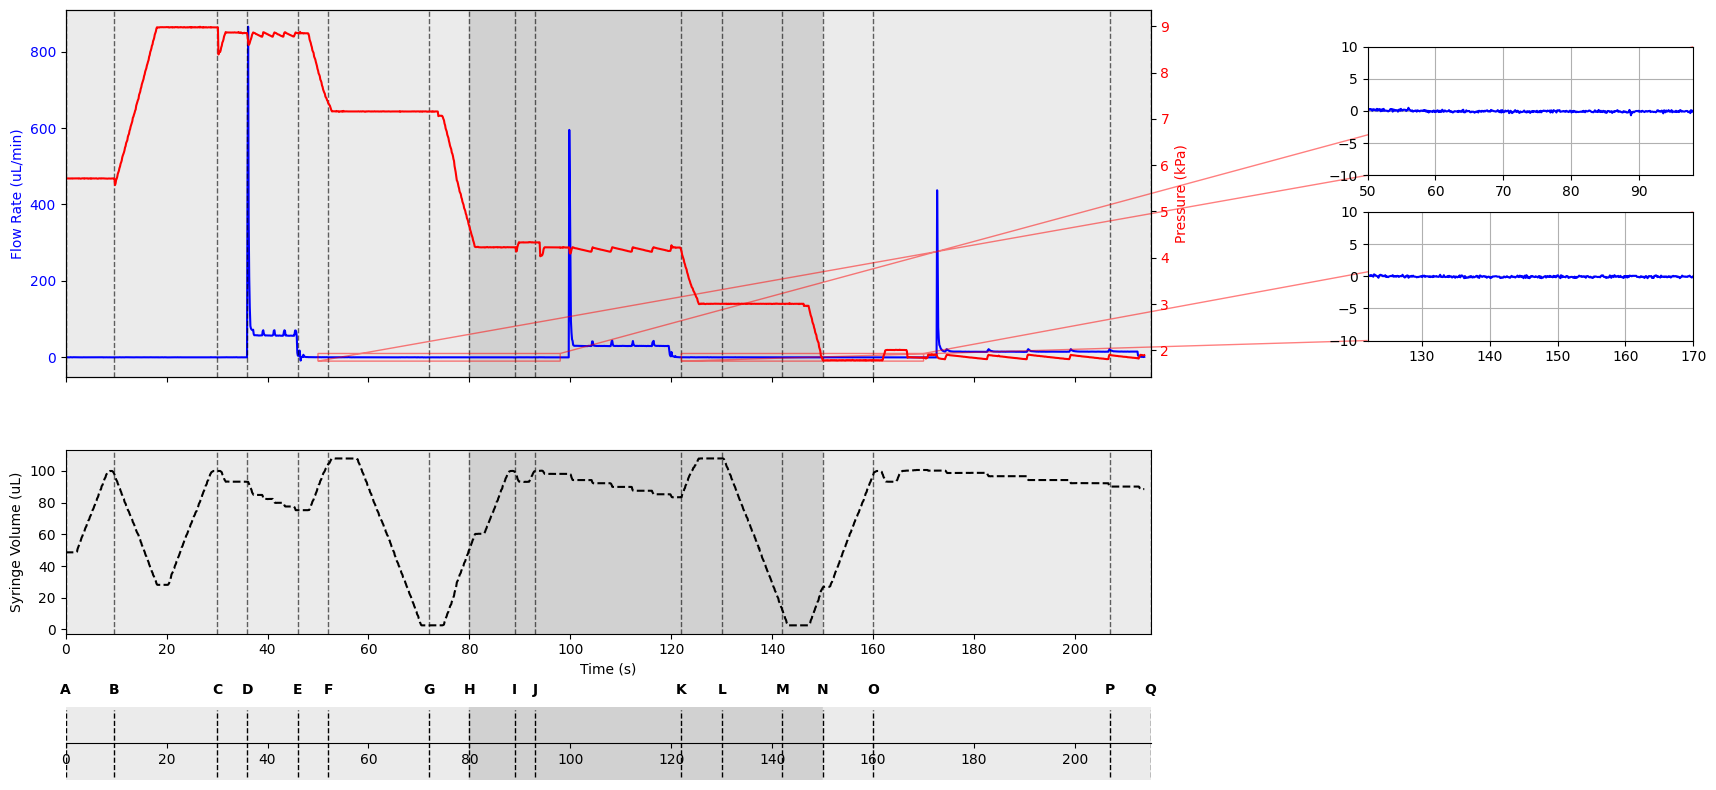

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# FIGURE LAYOUT
# -----------------------------
fig, (ax1, ax3, ax_timeline) = plt.subplots(
    3, 1, figsize=(14, 10),
    sharex=True,
    gridspec_kw={'height_ratios': [2, 1, 0.4]}
)

plt.subplots_adjust(hspace=0.35)

# -----------------------------
# ZOOM WINDOWS
# -----------------------------
zoom_start1, zoom_end1 = 50, 98
zoom_start2, zoom_end2 = 122, 170

df_zoom1 = df[(df['continuous_time_s'] >= zoom_start1) & (df['continuous_time_s'] <= zoom_end1)]
df_zoom2 = df[(df['continuous_time_s'] >= zoom_start2) & (df['continuous_time_s'] <= zoom_end2)]

# -----------------------------
# TOP PLOT — FLOW + PRESSURE
# -----------------------------
ax1.plot(df['continuous_time_s'], df[flow_col], color='blue')
ax1.set_ylabel("Flow Rate (uL/min)", color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

if pressure_col:
    ax2 = ax1.twinx()
    ax2.plot(df['continuous_time_s'], df[pressure_col], color='red')
    ax2.set_ylabel("Pressure (kPa)", color='red')
    ax2.tick_params(axis='y', labelcolor='red')

# -----------------------------
# MIDDLE PLOT — SYRINGE VOLUME
# -----------------------------
ax3.plot(df['continuous_time_s'], df[syringe_col], color='black', linestyle='--')
ax3.set_ylabel("Syringe Volume (uL)", color='black')
ax3.tick_params(axis='y', labelcolor='black')
ax3.set_xlabel("Time (s)")

# -----------------------------
# INSET ZOOMS (INSIDE AX1)
# -----------------------------
# Zoom 1
zm1 = ax1.inset_axes([1.2, 0.55, 0.3, 0.35])
zm1.plot(df_zoom1['continuous_time_s'], df_zoom1[flow_col], color='blue')
zm1.set_xlim(zoom_start1, zoom_end1)
zm1.set_ylim(-10, 10)
zm1.grid(True)

# Zoom 2
zm2 = ax1.inset_axes([1.2, 0.1, 0.3, 0.35])
zm2.plot(df_zoom2['continuous_time_s'], df_zoom2[flow_col], color='blue')
zm2.set_xlim(zoom_start2, zoom_end2)
zm2.set_ylim(-10, 10)
zm2.grid(True)

ax1.indicate_inset_zoom(zm1, edgecolor='red', lw=1)
ax1.indicate_inset_zoom(zm2, edgecolor='red', lw=1)

# -----------------------------
# EVENT DEFINITIONS (GROUPED)
# -----------------------------
events = {
    0:   "A – syringe fills with air",
    9.5: "B – pressurize",
    30:  "C – valve switch; push air",
    36:  "D – injection 1",
    46:  "E – end injection 1; pull air",
    52:  "F – dump air",
    72:  "G – pull air from reservoirs",
    80:  "H – p_target reached",
    89:  "I – valve switch; push air",
    93:  "J – injection 2",
    122: "K – end injection 2; pull air",
    130: "L – dump air",
    142: "M – pull air from reservoirs",
    150: "N – p_target reached",
    160: "O – valve switch; push air",
    207: "P – injection 3",
    215: "Q – end experiment",
}

event_times = sorted(events.keys())

# -----------------------------
# GROUPED PHASES (3 CYCLES)
# -----------------------------
# Cycle 1: A → H
# Cycle 2: I → N
# Cycle 3: O → Q

phase_groups = [
    (0, 80),    # Cycle 1
    (80, 150),  # Cycle 2
    (150, 215)  # Cycle 3
]

# Alternating grayscale shading
for i, (start, end) in enumerate(phase_groups):
    shade = 0.92 if i % 2 == 0 else 0.82
    ax1.axvspan(start, end, color=str(shade), alpha=1.0, zorder=0)
    ax3.axvspan(start, end, color=str(shade), alpha=1.0, zorder=0)
    ax_timeline.axvspan(start, end, color=str(shade), alpha=1.0, zorder=1)

# -----------------------------
# FULL-HEIGHT DOTTED LINES
# -----------------------------
for t in event_times:
    ax1.axvline(t, color='black', linestyle='--', linewidth=1, alpha=0.6)
    ax3.axvline(t, color='black', linestyle='--', linewidth=1, alpha=0.6)
    ax_timeline.vlines(t, -0.4, 0.4, color='black', linestyle='--', linewidth=1)

# -----------------------------
# TIMELINE LETTERS
# -----------------------------
ax_timeline.spines['top'].set_visible(False)
ax_timeline.spines['right'].set_visible(False)
ax_timeline.spines['left'].set_visible(False)
ax_timeline.spines['bottom'].set_position('center')
ax_timeline.yaxis.set_visible(False)

for t, full_label in events.items():
    letter = full_label.split("–")[0].strip()
    ax_timeline.text(
        t, 0.55, letter,
        ha='center', va='bottom',
        fontsize=10, fontweight='bold'
    )

# -----------------------------
# FINAL FORMATTING
# -----------------------------
max_time = max(df['continuous_time_s'].max(), max(event_times))
ax1.set_xlim(0, max_time)
ax3.set_xlim(0, max_time)
ax_timeline.set_xlim(0, max_time)

ax_timeline.set_xticks([])
ax3.set_xticks(np.arange(0, max_time+1, 20))
ax3.tick_params(axis='x', labelbottom=True)

plt.show()


# Zoom in on flow to see how quickly it stabilizes 

/var/folders/53/zmgmptt14xq2nbqsrnm6qm4r0000gn/T/ipykernel_29543/3074305503.py:41: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


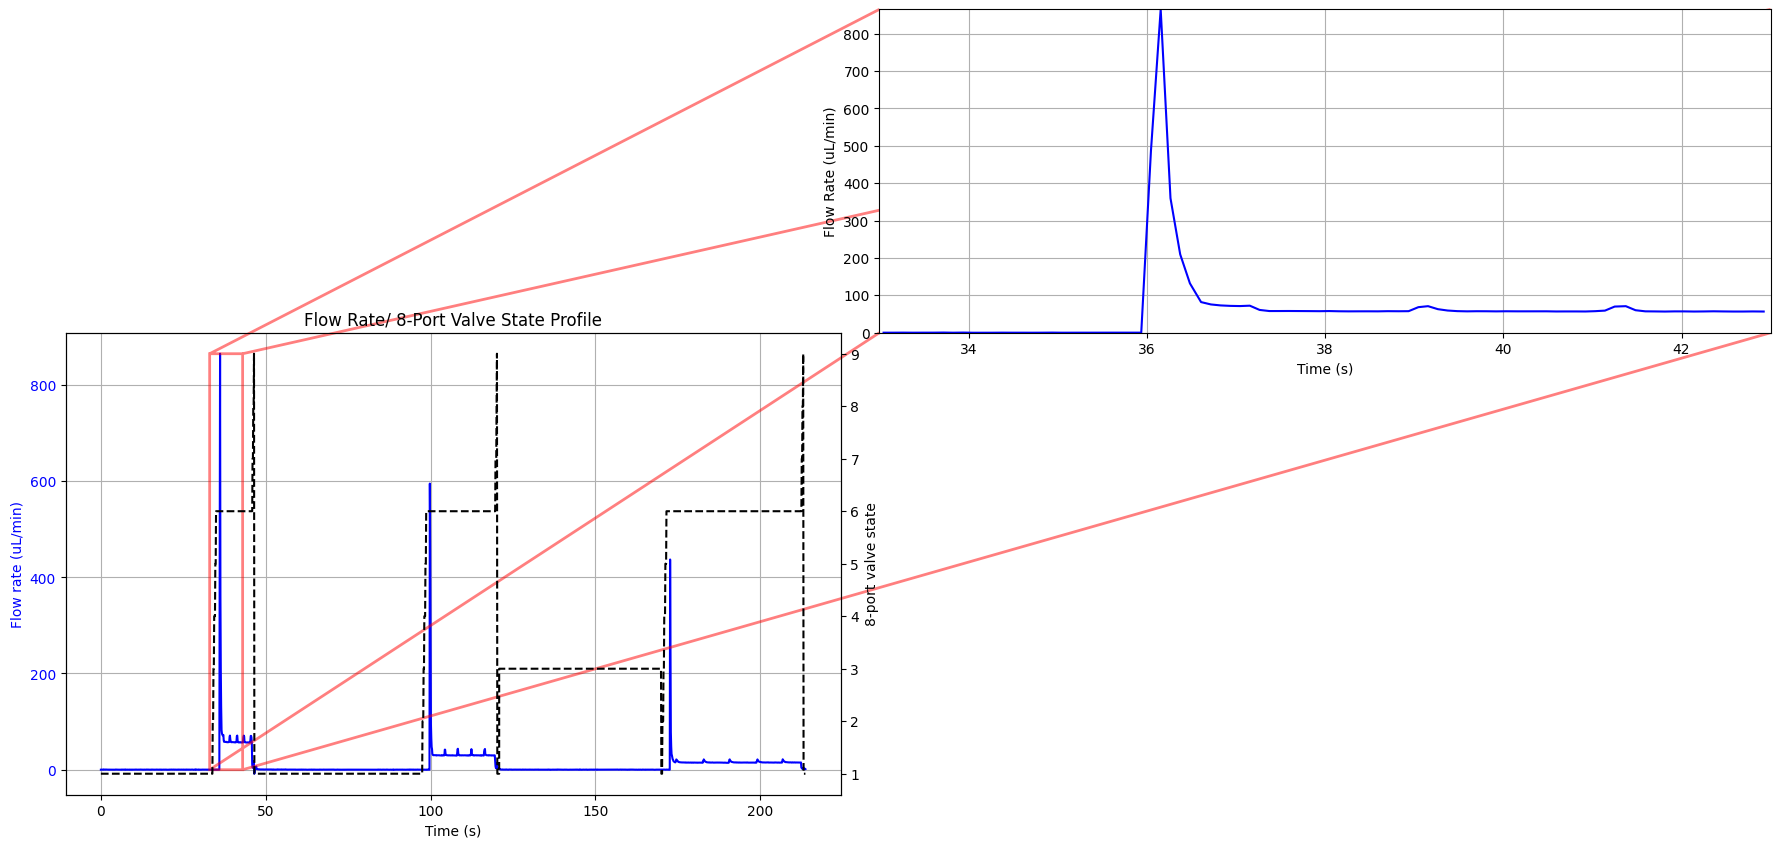

In [ ]:
import matplotlib.pyplot as plt

# Zoom range
zoom_start = 33
zoom_end = 43

# Slice for zoom
df_zoom = df[(df['continuous_time_s'] >= zoom_start) & (df['continuous_time_s'] <= zoom_end)]

# Create main plot
fig, ax1 = plt.subplots(figsize=(10, 6))

# Primary Y-axis: flow
ax1.plot(df['continuous_time_s'], df[flow_col], color='blue', label='Flow Rate')
ax1.set_xlabel('Time (s)')
ax1.set_ylabel('Flow rate (uL/min)', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# Secondary Y-axis: valve state (if available)
if pressure_col and valve_col:
    ax2 = ax1.twinx()
    ax2.plot(df['continuous_time_s'], df[valve_col], color='black', linestyle='--')
    ax2.set_ylabel('8-port valve state', color='black')
    ax2.tick_params(axis='y', labelcolor='black')

# Add zoomed inset for flow
zm = ax1.inset_axes([1.05, 1.0, 1.15, 0.7])  # [x, y, width, height] in axes fraction
zm.plot(df_zoom['continuous_time_s'], df_zoom[flow_col], color='blue')
zm.set_xlabel('Time (s)')
zm.set_ylabel('Flow Rate (uL/min)')
zm.set_xlim(zoom_start, zoom_end)
zm.set_ylim(df_zoom[flow_col].min(), df_zoom[flow_col].max())
zm.grid(True)

# Indicate inset on main plot
ax1.indicate_inset_zoom(zm, edgecolor='red', lw = 2)

# Final touches
plt.title('Flow Rate/ 8-Port Valve State Profile')
ax1.grid(True)
fig.tight_layout()
plt.show()


# Analyze peak-to-peak flow for one experiment 

Peak-to-peak flow rate during dispense: 29.90 uL/min


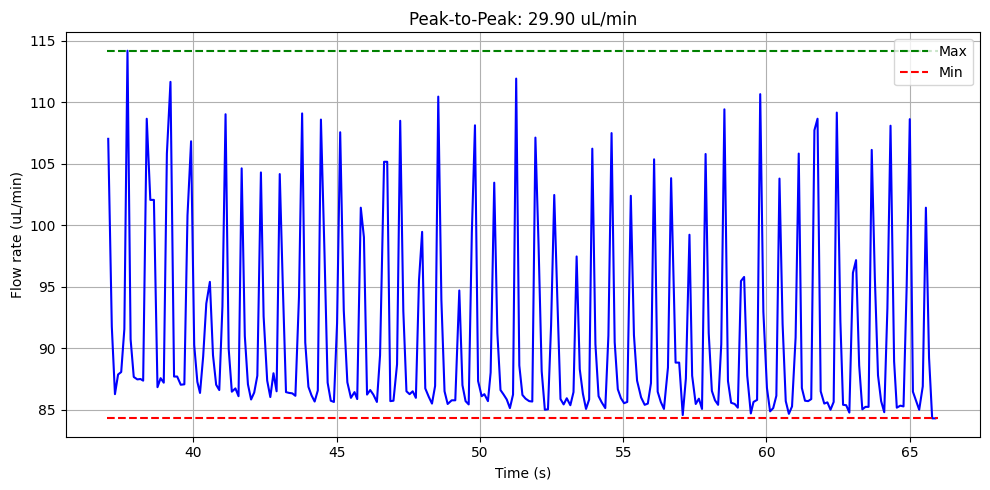

In [ ]:
# Define dispense time window (adjust as needed)
disp_start = 37
disp_end = 66

# Filter data for that time range
df_disp = df[(df['continuous_time_s'] >= disp_start) & (df['continuous_time_s'] <= disp_end)]

# Compute peak-to-peak flow
peak_to_peak = df_disp[flow_col].max() - df_disp[flow_col].min()
print(f"Peak-to-peak flow rate during dispense: {peak_to_peak:.2f} uL/min")

# Plot zoomed-in flow with P2P annotation
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(df_disp['continuous_time_s'], df_disp[flow_col], color='blue')
ax.set_xlabel('Time (s)')
ax.set_ylabel('Flow rate (uL/min)')
ax.set_title(f"Peak-to-Peak: {peak_to_peak:.2f} uL/min")
ax.grid(True)

# Optional: mark peaks
ax.hlines(df_disp[flow_col].max(), disp_start, disp_end, colors='green', linestyles='--', label='Max')
ax.hlines(df_disp[flow_col].min(), disp_start, disp_end, colors='red', linestyles='--', label='Min')
ax.legend()

plt.tight_layout()
plt.show()


# Analyze peak-to-peak flow for different experiments and for varying flow rates

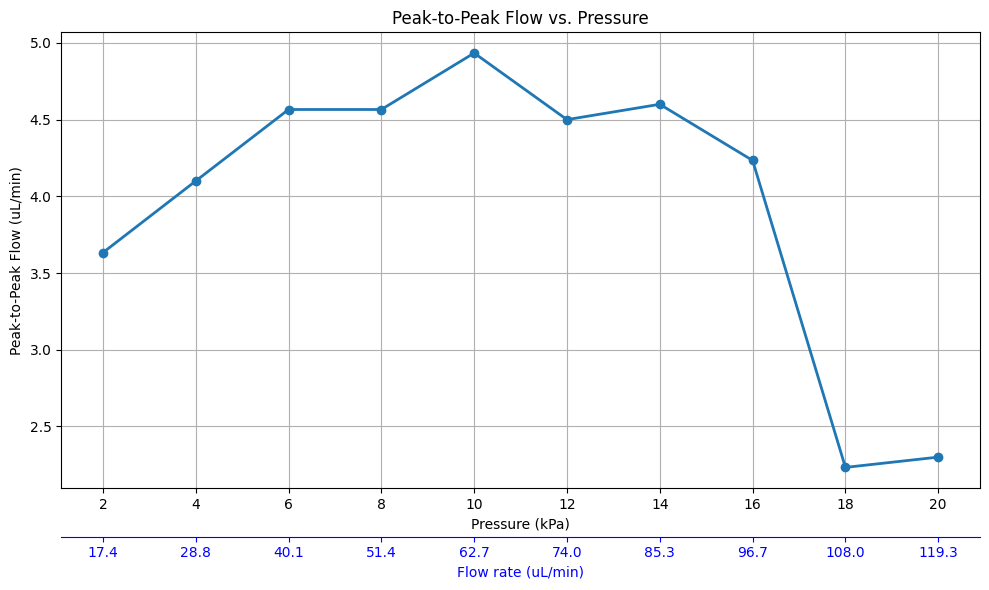

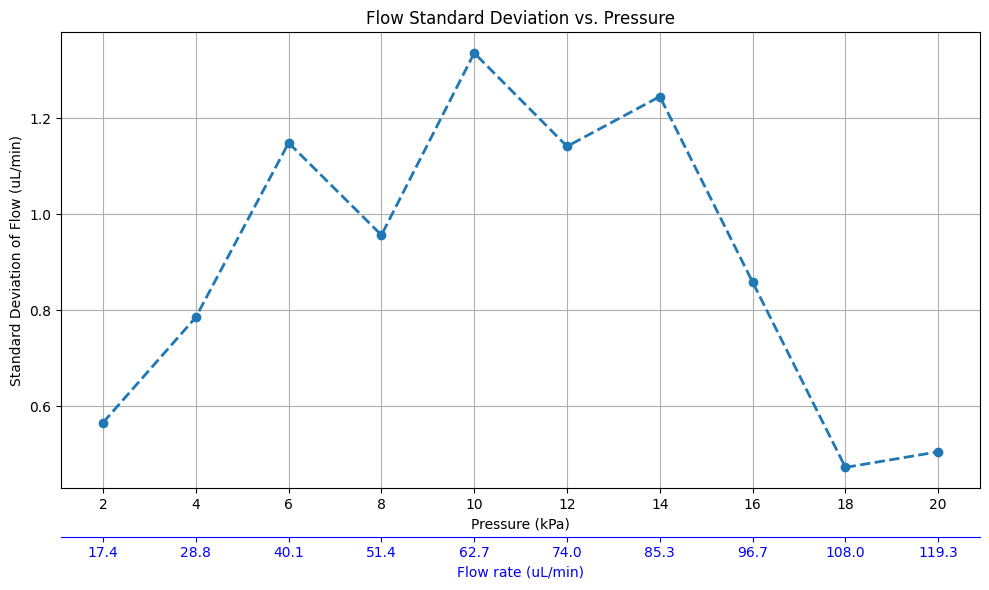

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# 1m peek calibration curve
folder_path = './1m_PEEK_calibration'
time_col = 'Time (s)'
flow_col = 'SF06_5: ()'
window_start = 10
window_end = 20

trial = 3  


p2p_results = []   
std_results = []   
def add_flow_xaxis_below(ax):
    pressures = list(range(2, 21, 2))
    flow_labels = [f"{5.658*p + 6.122:.1f}" for p in pressures]  # flow at each pressure

    sec = ax.secondary_xaxis('bottom')   # shares same x scale as primary
    sec.set_xticks(pressures)
    sec.set_xticklabels(flow_labels)
    sec.set_xlabel("Flow rate (uL/min)")

    # push it below the main x-axis
    sec.spines['bottom'].set_position(('outward', 35))

    # make it red
    sec.tick_params(axis='x', colors='blue')
    sec.xaxis.label.set_color('blue')
    sec.spines['bottom'].set_color('blue')

    return sec


for pressure_kpa in range(2, 21, 2):  
    filename = f"calib_{pressure_kpa}kPa_trial{trial}.csv"
    file_path = os.path.join(folder_path, filename)

    df = pd.read_csv(file_path, sep=';', skiprows=1)
    df.columns = df.columns.str.strip()
    df[time_col] = pd.to_numeric(df[time_col], errors='coerce')
    df[flow_col] = pd.to_numeric(df[flow_col], errors='coerce')
    df = df.dropna(subset=[time_col, flow_col])

    df_window = df[(df[time_col] >= window_start) & (df[time_col] <= window_end)]

    peak_to_peak = df_window[flow_col].max() - df_window[flow_col].min()
    std = df_window[flow_col].std()

    p2p_results.append((pressure_kpa, peak_to_peak))
    std_results.append((pressure_kpa, std))

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(*zip(*p2p_results), 'o-', linewidth=2)
ax.set_xlabel("Pressure (kPa)")
ax.set_ylabel("Peak-to-Peak Flow (uL/min)")
ax.set_xticks(range(2, 21, 2))
ax.set_title("Peak-to-Peak Flow vs. Pressure")
ax.grid(True)

add_flow_xaxis_below(ax)

fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(*zip(*std_results), 'o--', linewidth=2)
ax.set_xlabel("Pressure (kPa)")
ax.set_ylabel("Standard Deviation of Flow (uL/min)")
ax.set_xticks(range(2, 21, 2))
ax.set_title("Flow Standard Deviation vs. Pressure")
ax.grid(True)

add_flow_xaxis_below(ax)

fig.tight_layout()
plt.show()


Peak-to-Peak Flow (15–30s window):
 2 kPa: 9.13 uL/min
 4 kPa: 10.43 uL/min
 6 kPa: 11.57 uL/min
 8 kPa: 11.00 uL/min
10 kPa: 11.80 uL/min
12 kPa: 11.00 uL/min
14 kPa: 21.73 uL/min
16 kPa: 15.57 uL/min
18 kPa: 19.30 uL/min
20 kPa: 16.27 uL/min


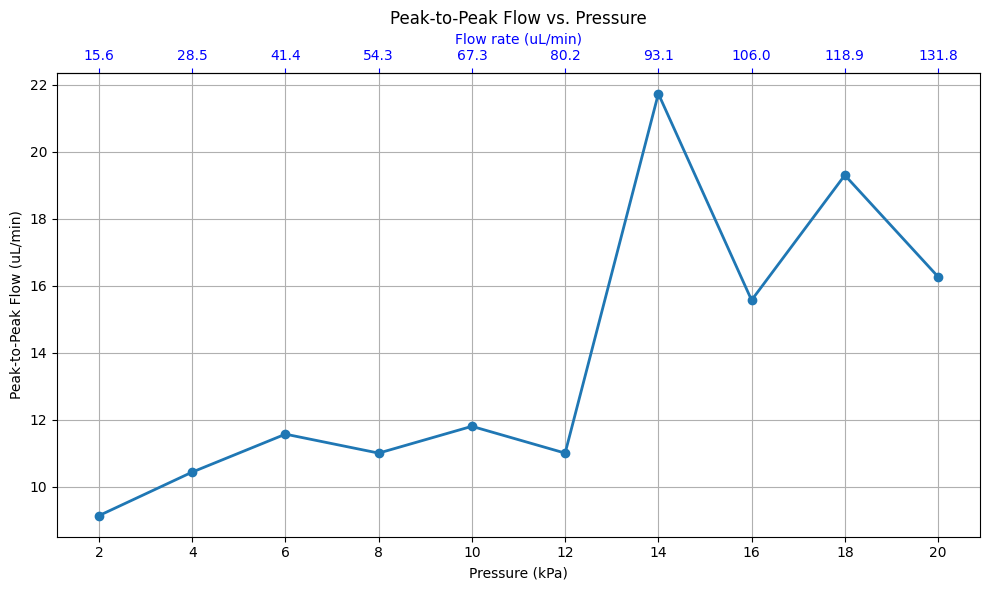

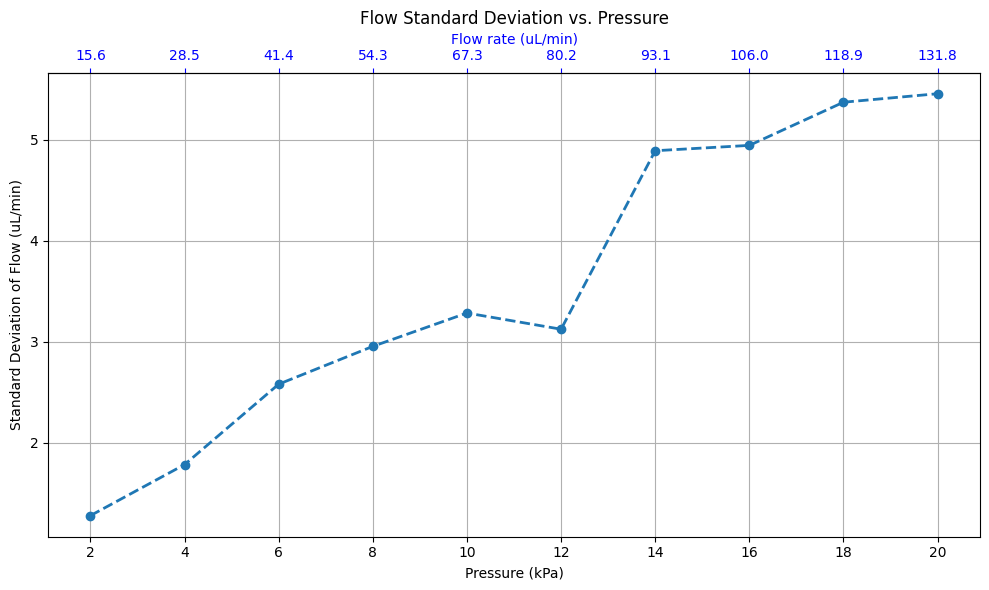

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt


folder_path = './ReactionChamberChip_calibration'
time_col = 'Time (s)'
flow_col = 'SF06_5: ()'
window_start = 15
window_end = 30

trial_map = {
    2: 1,
    4: 1,
    6: 1,
    8: 1,
    10: 1,
    12: 1,
    14: 4,
    16: 1,
    18: 3,
    20: 2
}

results = []
std_results = []
#Loop through each specified pressure/trial pair 
for pressure_kpa, trial in trial_map.items():
    filename = f"calib_{pressure_kpa}kPa_trial{trial}.csv"
    file_path = os.path.join(folder_path, filename)

    df = pd.read_csv(file_path, sep=';', skiprows=1)
    df.columns = df.columns.str.strip()
    df[time_col] = pd.to_numeric(df[time_col], errors='coerce')
    df[flow_col] = pd.to_numeric(df[flow_col], errors='coerce')
    df = df.dropna(subset=[time_col, flow_col])

    df_window = df[(df[time_col] >= window_start) & (df[time_col] <= window_end)]

    peak_to_peak = df_window[flow_col].max() - df_window[flow_col].min()
    results.append((pressure_kpa, peak_to_peak))
    std = df_window[flow_col].std()
    std_results.append((pressure_kpa, std))
print(f"\nPeak-to-Peak Flow ({window_start}–{window_end}s window):")
for pressure, p2p in sorted(results):
    print(f"{pressure:>2} kPa: {p2p:.2f} uL/min")

def add_flow_xaxis_below(ax):
    pressures = list(range(2, 21, 2))
    flow_labels = [f"{6.457*p + 2.684:.1f}" for p in pressures]  # flow at each pressure

    sec = ax.secondary_xaxis('top')   # shares same x scale as primary
    sec.set_xticks(pressures)
    sec.set_xticklabels(flow_labels)
    sec.set_xlabel("Flow rate (uL/min)")

    # push it below the main x-axis
    sec.spines['bottom'].set_position(('outward', 35))

    # make it red
    sec.tick_params(axis='x', colors='blue')
    sec.xaxis.label.set_color('blue')
    sec.spines['bottom'].set_color('blue')

    return sec

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(*zip(*results), 'o-', linewidth=2)
ax.set_xlabel("Pressure (kPa)")
ax.set_ylabel("Peak-to-Peak Flow (uL/min)")
ax.set_xticks(range(2, 21, 2))
ax.set_title("Peak-to-Peak Flow vs. Pressure")
ax.grid(True)

add_flow_xaxis_below(ax)

fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(*zip(*std_results), 'o--', linewidth=2)
ax.set_xlabel("Pressure (kPa)")
ax.set_ylabel("Standard Deviation of Flow (uL/min)")
ax.set_xticks(range(2, 21, 2))
ax.set_title("Flow Standard Deviation vs. Pressure")
ax.grid(True)

add_flow_xaxis_below(ax)
plt.tight_layout()
plt.show()









# Pressure driven flow is more stable than direct flow 

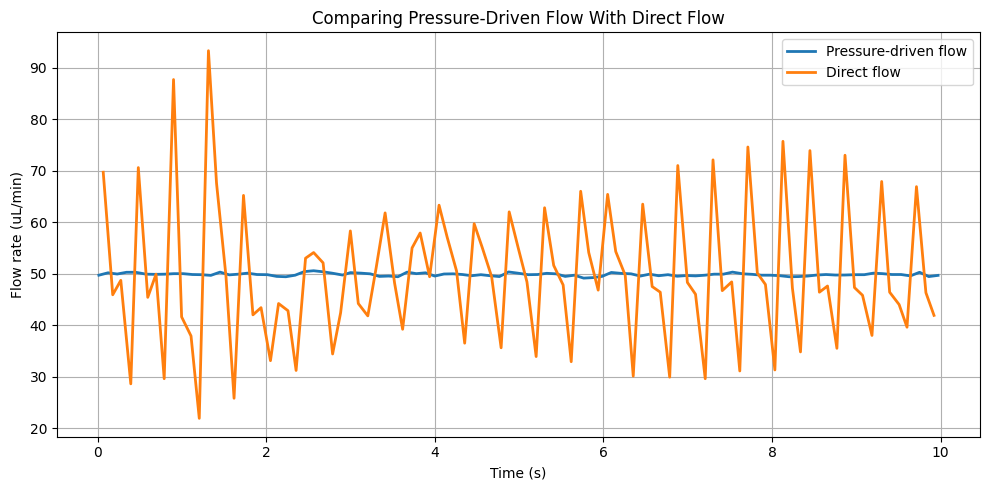


Pressure-driven flow
Mean in the window : 49.83 uL/min
Std  in the window: 0.29 uL/min

Direct flow
Mean in the window: 49.78 uL/min
Std  in the window: 13.81 uL/min
143    69.7
144    45.9
145    48.7
146    28.6
147    70.6
       ... 
233    44.0
234    39.6
235    66.9
236    46.3
237    41.9
Name: F_SLF3S_600_2521000069, Length: 95, dtype: float64
135    49.700
136    50.167
137    49.933
138    50.267
139    50.267
        ...  
221    49.833
222    49.567
223    50.267
224    49.433
225    49.667
Name: SF06_5: (), Length: 91, dtype: float64


In [ ]:
# Used 1m_PEEK tubing; GUI to figure out the right pressure for 50uL/min and ran for 30seconds 
# For direct flow, pulled DI water from reservoir, pushed it with syringe and measured with flow sensor 

PDF_FILE = 'PDF_50uL.csv'
DIRECT_FILE = '50uL_min.csv'

import pandas as pd
import matplotlib.pyplot as plt

WINDOW_START = 15    # seconds
WINDOW_END   = 25   # seconds

def load_pressure_driven(path):
    df = pd.read_csv(
        path,
        skiprows=1,          
        sep=None,
        engine="python",
        on_bad_lines="skip"
    )

    time_col = "Time (s)" if "Time (s)" in df.columns else df.columns[0]
    flow_col = [c for c in df.columns if "sf" in c.lower() or "flow" in c.lower()][0]

    df[time_col] = pd.to_numeric(df[time_col], errors="coerce")
    df[flow_col] = pd.to_numeric(df[flow_col], errors="coerce")
    df = df.dropna(subset=[time_col, flow_col])

    df[time_col] -= df[time_col].iloc[0]

    return df, time_col, flow_col


def load_direct_flow(path):
    import pandas as pd
    import re
    from io import StringIO

    # ---------- Read raw lines ----------
    with open(path, "r") as f:
        lines = f.readlines()

    # ---------- Find header row dynamically ----------
    header_idx = None
    for i, line in enumerate(lines):
        if "F_SLF3S" in line:
            header_idx = i
            break



    header_line = lines[header_idx].strip()
    data_lines  = lines[header_idx + 1 :]

    raw_headers = re.split(r"\s+", header_line)

    headers = []
    seen = {}
    for h in raw_headers:
        if h in seen:
            seen[h] += 1
            h = f"{h}_{seen[h]}"
        else:
            seen[h] = 0
        headers.append(h)
    # ---------- Load data using same whitespace rule ----------
    df = pd.read_csv(
        StringIO("".join(data_lines)),
        sep=r"\s+",
        names=headers,
        engine="python"
    )

    time_col = "Epoch_UTC"
    if time_col not in df.columns:
        raise ValueError("Epoch_UTC column not found")

    flow_cols = [c for c in df.columns if "F_SLF3S" in c]
    if not flow_cols:
        raise ValueError(f"No F_SLF3S column found. Columns seen: {df.columns.tolist()}")

    flow_col = flow_cols[0]

    df[time_col] = pd.to_numeric(df[time_col], errors="coerce")
    df[flow_col] = pd.to_numeric(df[flow_col], errors="coerce")
    df = df.dropna(subset=[time_col, flow_col])

    df["time_s"] = df[time_col] - df[time_col].iloc[0]

    return df, "time_s", flow_col



pdf_df, pdf_t, pdf_f = load_pressure_driven(PDF_FILE)
dir_df, dir_t, dir_f = load_direct_flow(DIRECT_FILE)

def window_stats(df, t_col, f_col):
    w = df[(df[t_col] >= WINDOW_START) & (df[t_col] <= WINDOW_END)]
    return w[f_col].mean(), w[f_col].std()

pdf_mean, pdf_std = window_stats(pdf_df, pdf_t, pdf_f)
dir_mean, dir_std = window_stats(dir_df, dir_t, dir_f)

pdf_df, pdf_t, pdf_f = load_pressure_driven(PDF_FILE)
dir_df, dir_t, dir_f = load_direct_flow(DIRECT_FILE)

def window_stats(df, t_col, f_col):
    w = df[(df[t_col] >= WINDOW_START) & (df[t_col] <= WINDOW_END)]
    return w[f_col].mean(), w[f_col].std()

pdf_mean, pdf_std = window_stats(pdf_df, pdf_t, pdf_f)
dir_mean, dir_std = window_stats(dir_df, dir_t, dir_f)

def window_slice(df, t_col, f_col, t0, t1):
    return df[(df[t_col] >= t0) & (df[t_col] <= t1)][[t_col, f_col]]

pdf_win = window_slice(pdf_df, pdf_t, pdf_f, WINDOW_START, WINDOW_END)
dir_win = window_slice(dir_df, dir_t, dir_f, WINDOW_START, WINDOW_END)
pdf_win[pdf_t] -= WINDOW_START
dir_win[dir_t] -= WINDOW_START

plt.figure(figsize=(10, 5))

plt.plot(pdf_win[pdf_t], pdf_win[pdf_f],
         label="Pressure-driven flow", linewidth=2)

plt.plot(dir_win[dir_t], dir_win[dir_f],
         label="Direct flow", linewidth=2)

plt.xlabel("Time (s)")
plt.ylabel("Flow rate (uL/min)")
plt.grid(True)
plt.legend()
plt.title("Comparing Pressure-Driven Flow With Direct Flow")
plt.tight_layout()
plt.show()

print("\nPressure-driven flow")
print(f"Mean in the window : {pdf_mean:.2f} uL/min")
print(f"Std  in the window: {pdf_std:.2f} uL/min")

print("\nDirect flow")
print(f"Mean in the window: {dir_mean:.2f} uL/min")
print(f"Std  in the window: {dir_std:.2f} uL/min")
print(dir_win[dir_f])
print(pdf_win[pdf_f])

# Depressurization Plot

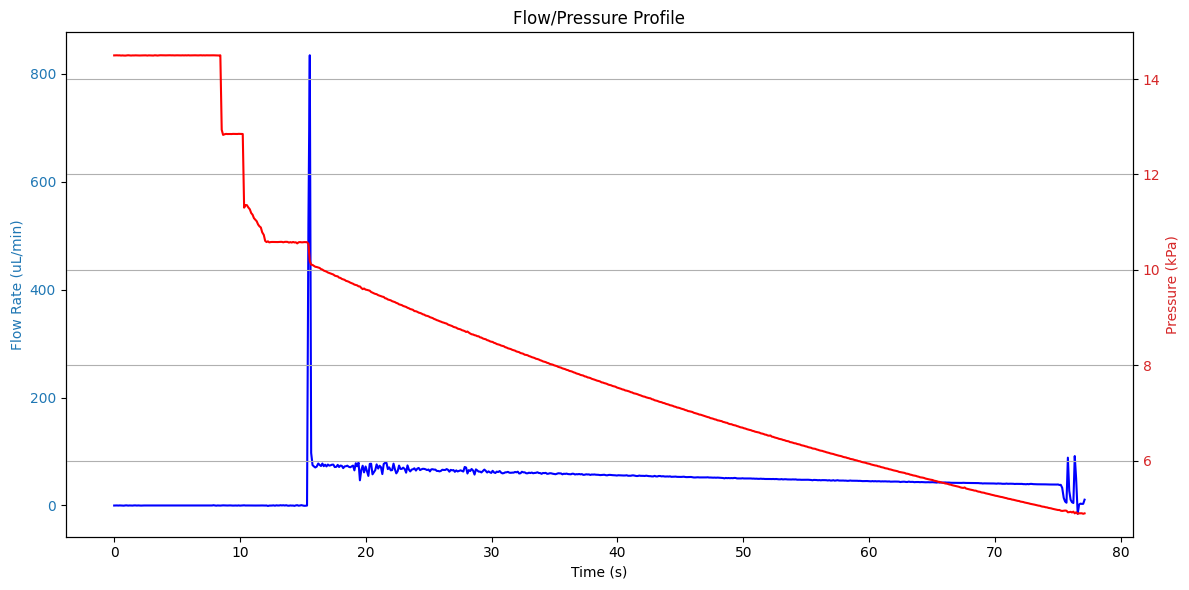

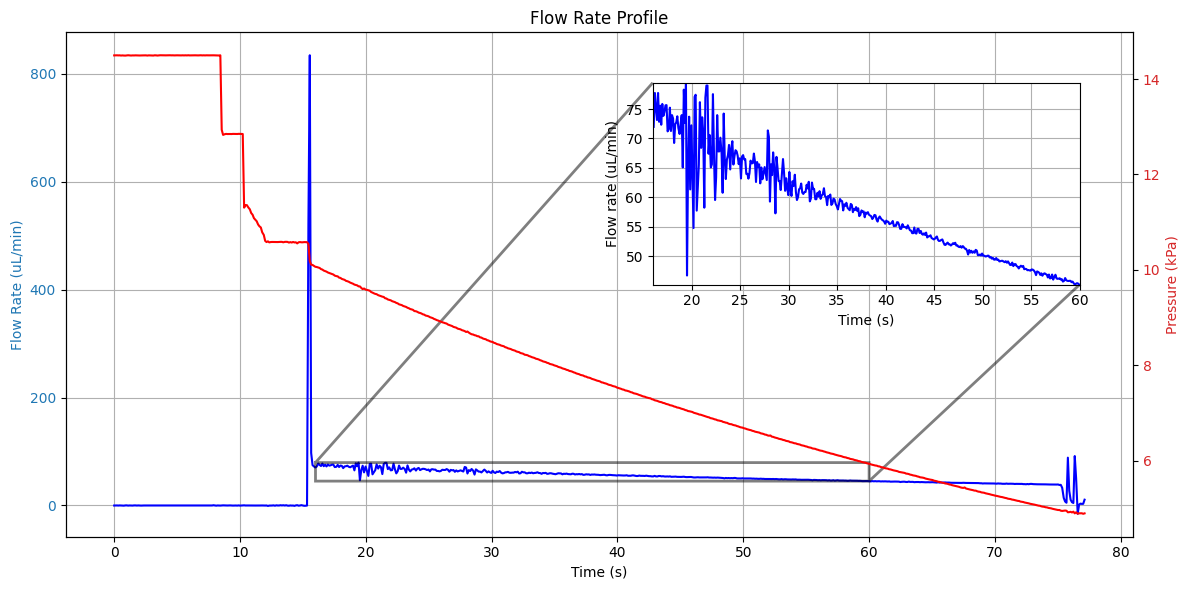

In [ ]:
csv = './exp_020226/ReactionChamberChip_RES4_R1_20260202_133252.csv'
time_col = 'Time (s)'
flow_col = 'SF06_5: ()'
df = pd.read_csv(csv, sep=';', skiprows=1)
df.columns = df.columns.str.strip()
df[time_col] = pd.to_numeric(df[time_col], errors='coerce')
df[flow_col] = pd.to_numeric(df[flow_col], errors='coerce')
continuous_time = []
offset = 0
prev_time = 0

for i, t in enumerate(df[time_col]):
    if i > 0 and t < df[time_col].iloc[i - 1]:  # Detected reset
        offset += df[time_col].iloc[i - 1]
    continuous_time.append(t + offset)

df['continuous_time_s'] = continuous_time

fig, ax1 = plt.subplots(figsize=(12, 6))

# Primary Y-axis
ax1.plot(df['continuous_time_s'], df[flow_col], color='blue', label=flow_col)
ax1.set_xlabel('Time (s)')
ax1.set_ylabel('Flow Rate (uL/min)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')

# Secondary Y-axis (if pressure column exists)
if pressure_col:
    ax2 = ax1.twinx()
    ax2.plot(df['continuous_time_s'], df[pressure_col], color='red', label=pressure_col)
    ax2.set_ylabel('Pressure (kPa)', color='tab:red')
    ax2.tick_params(axis='y', labelcolor='tab:red')

# Title and layout
plt.title('Flow/Pressure Profile')
fig.tight_layout()
plt.grid(True)
plt.show()

# Add zoomed inset for flow
fig, ax1 = plt.subplots(figsize=(12, 6))

#Main plot
ax1.plot(df['continuous_time_s'], df[flow_col], color='blue')
ax1.set_xlabel('Time (s)')
ax1.set_ylabel('Flow Rate (uL/min)')
ax1.set_ylabel('Flow Rate (uL/min)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid(True)
if pressure_col:
    ax2 = ax1.twinx()
    ax2.plot(df['continuous_time_s'], df[pressure_col], color='red', label=pressure_col)
    ax2.set_ylabel('Pressure (kPa)', color='tab:red')
    ax2.tick_params(axis='y', labelcolor='tab:red')

# Zoom range
zoom_start = 16
zoom_end = 60

# Slice for zoom
df_zoom = df[
    (df['continuous_time_s'] >= zoom_start) &
    (df['continuous_time_s'] <= zoom_end)
]

# Inset axes
zm = ax1.inset_axes([0.55, 0.5, 0.4, 0.4])  # [x, y, width, height]
zm.plot(df_zoom['continuous_time_s'], df_zoom[flow_col], color='blue')
zm.set_xlim(zoom_start, zoom_end)
zm.set_ylim(df_zoom[flow_col].min(), df_zoom[flow_col].max())
zm.set_xlabel("Time (s)")
zm.set_ylabel("Flow rate (uL/min)")
zm.grid(True)


ax1.indicate_inset_zoom(zm, edgecolor='black', lw=2)

ax1.set_title('Flow Rate Profile')

fig.tight_layout()
plt.show()



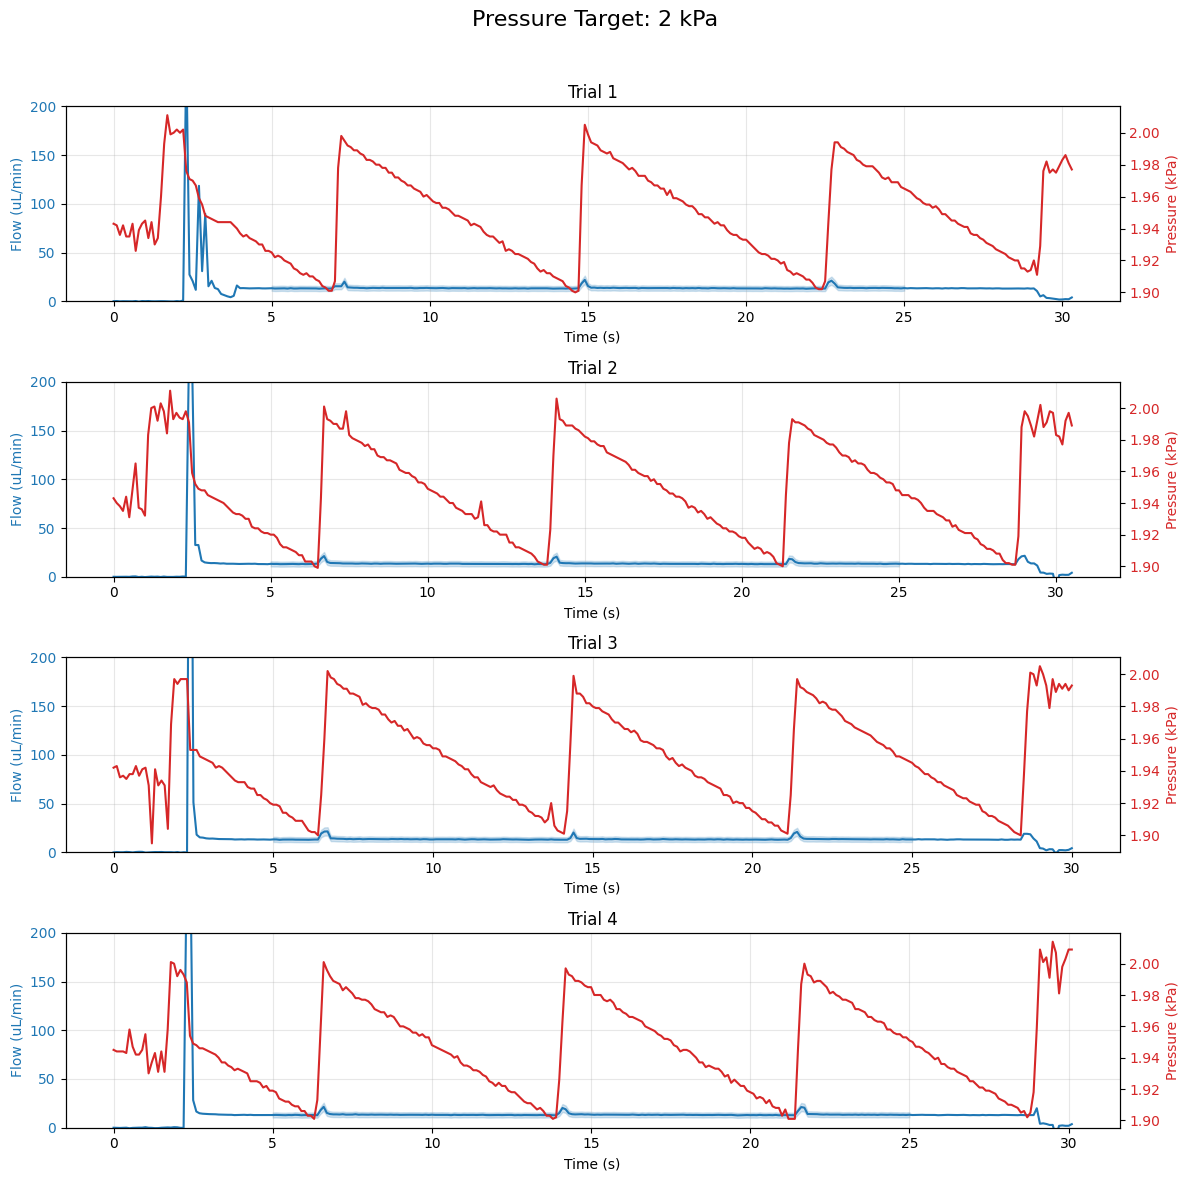

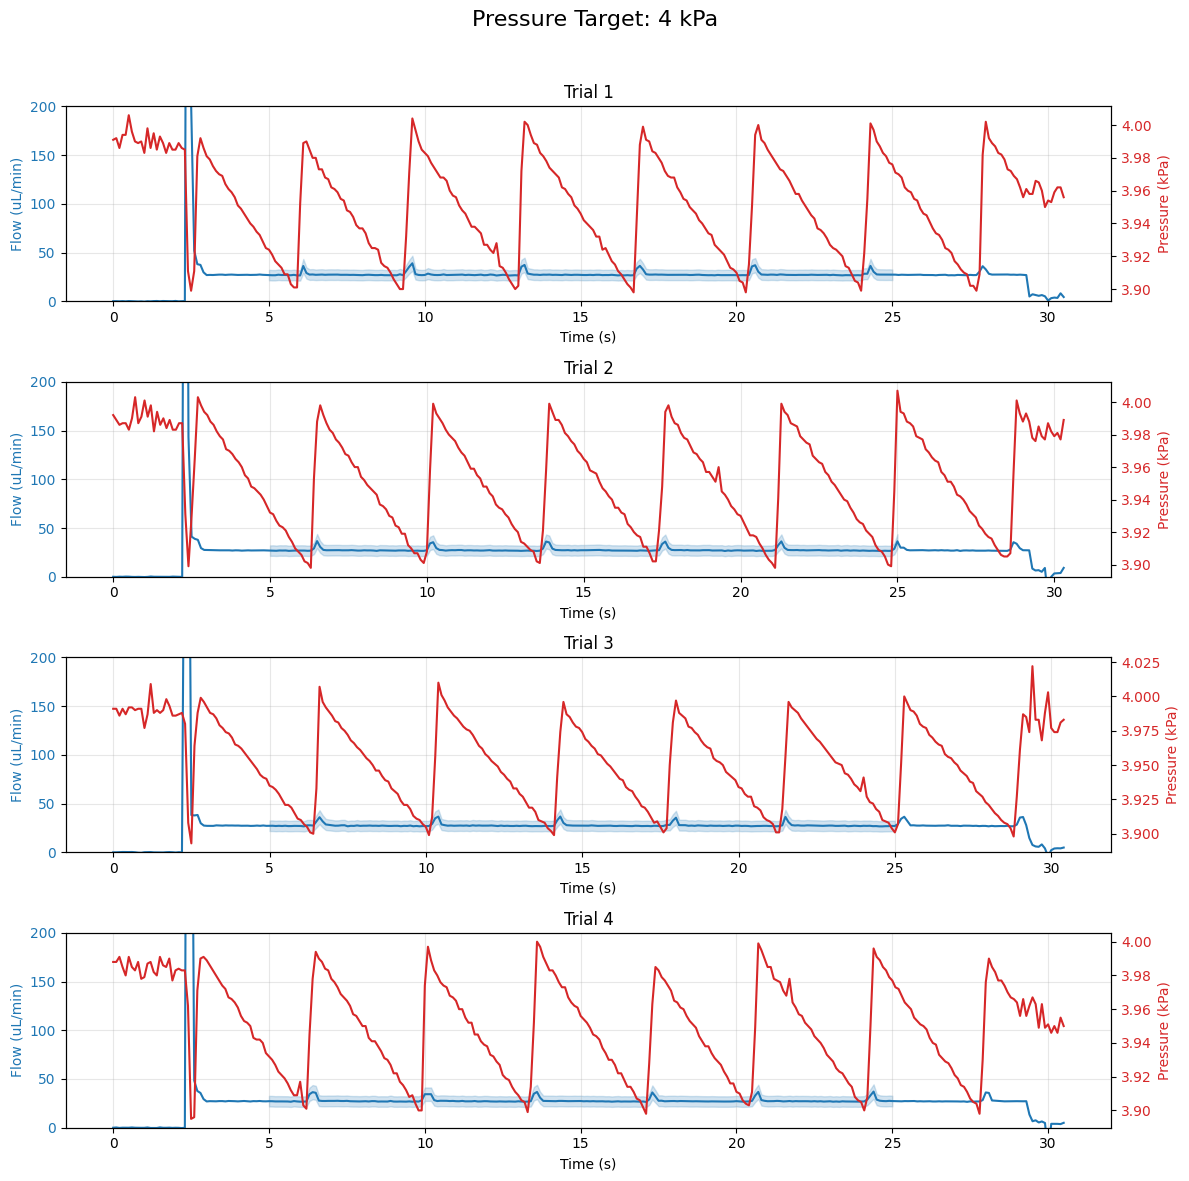

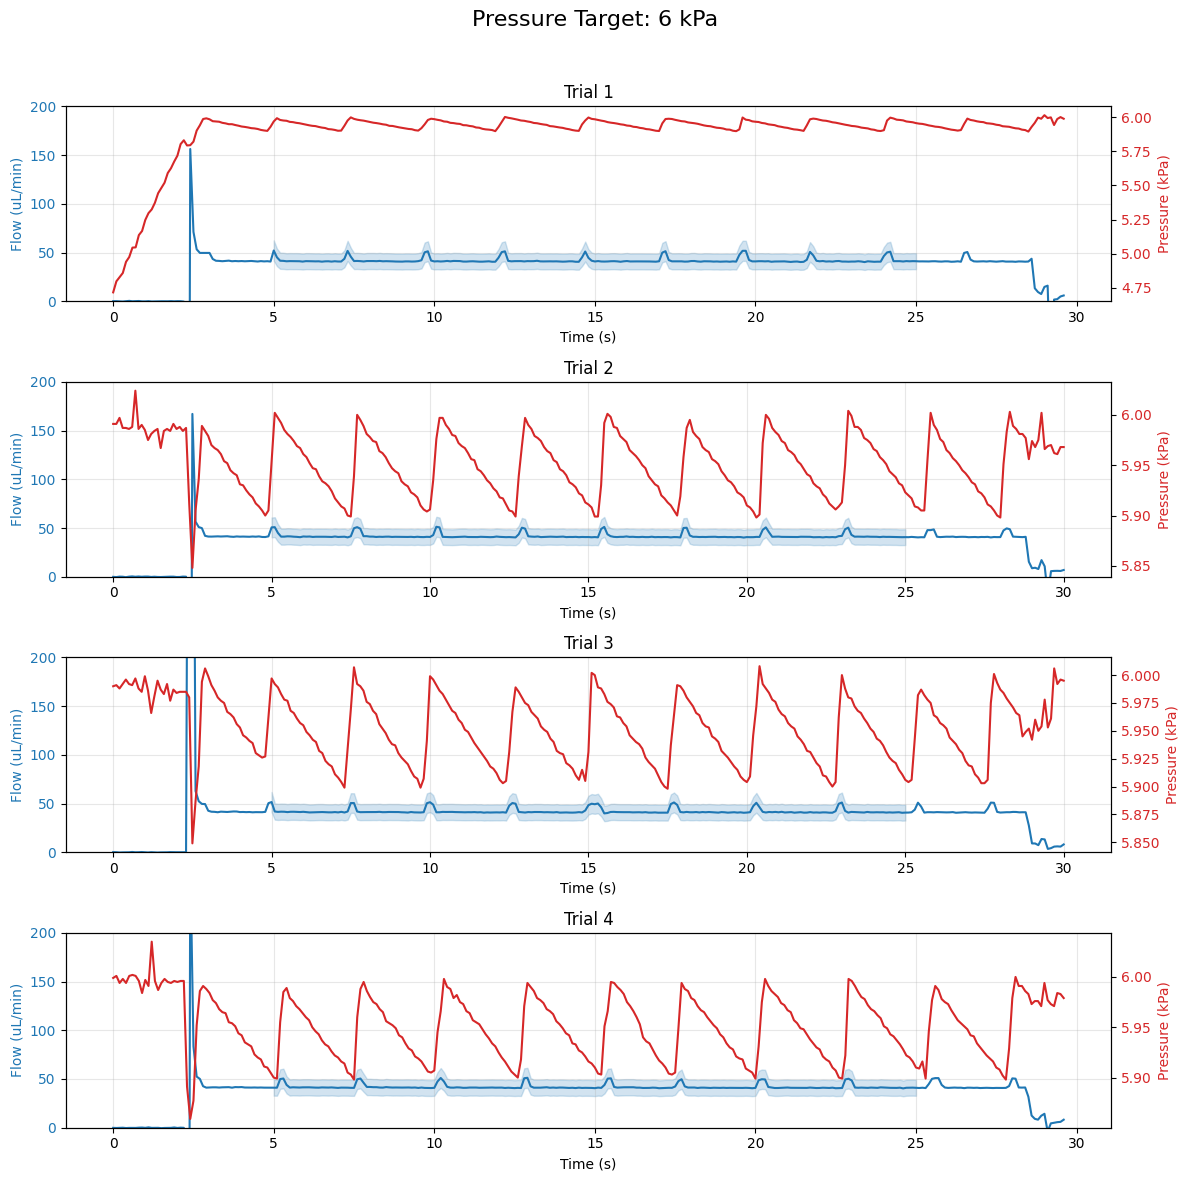

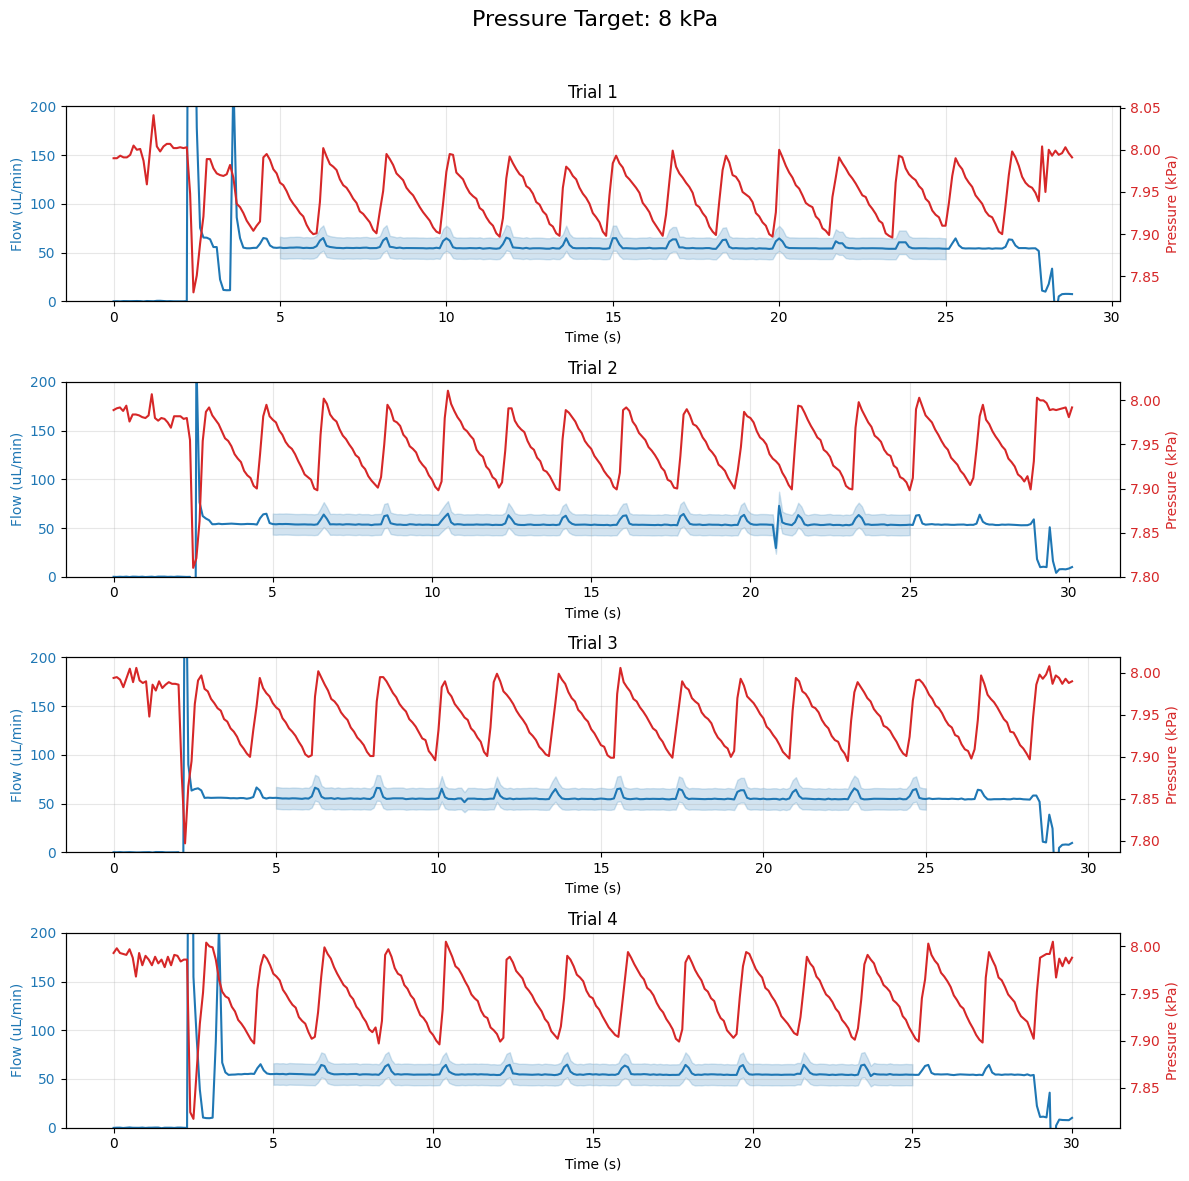

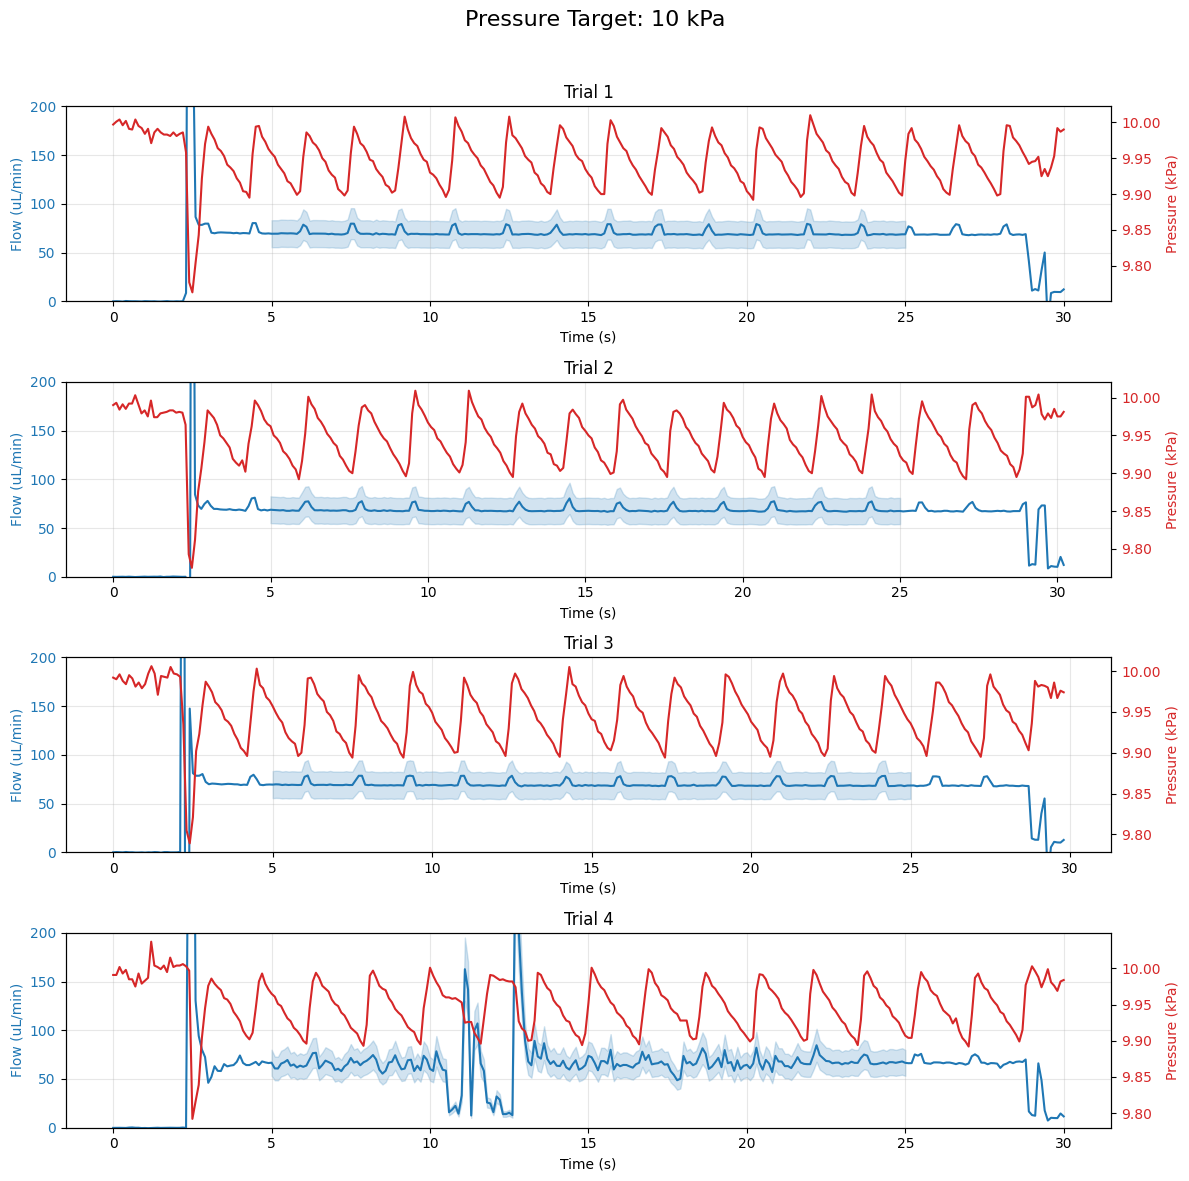

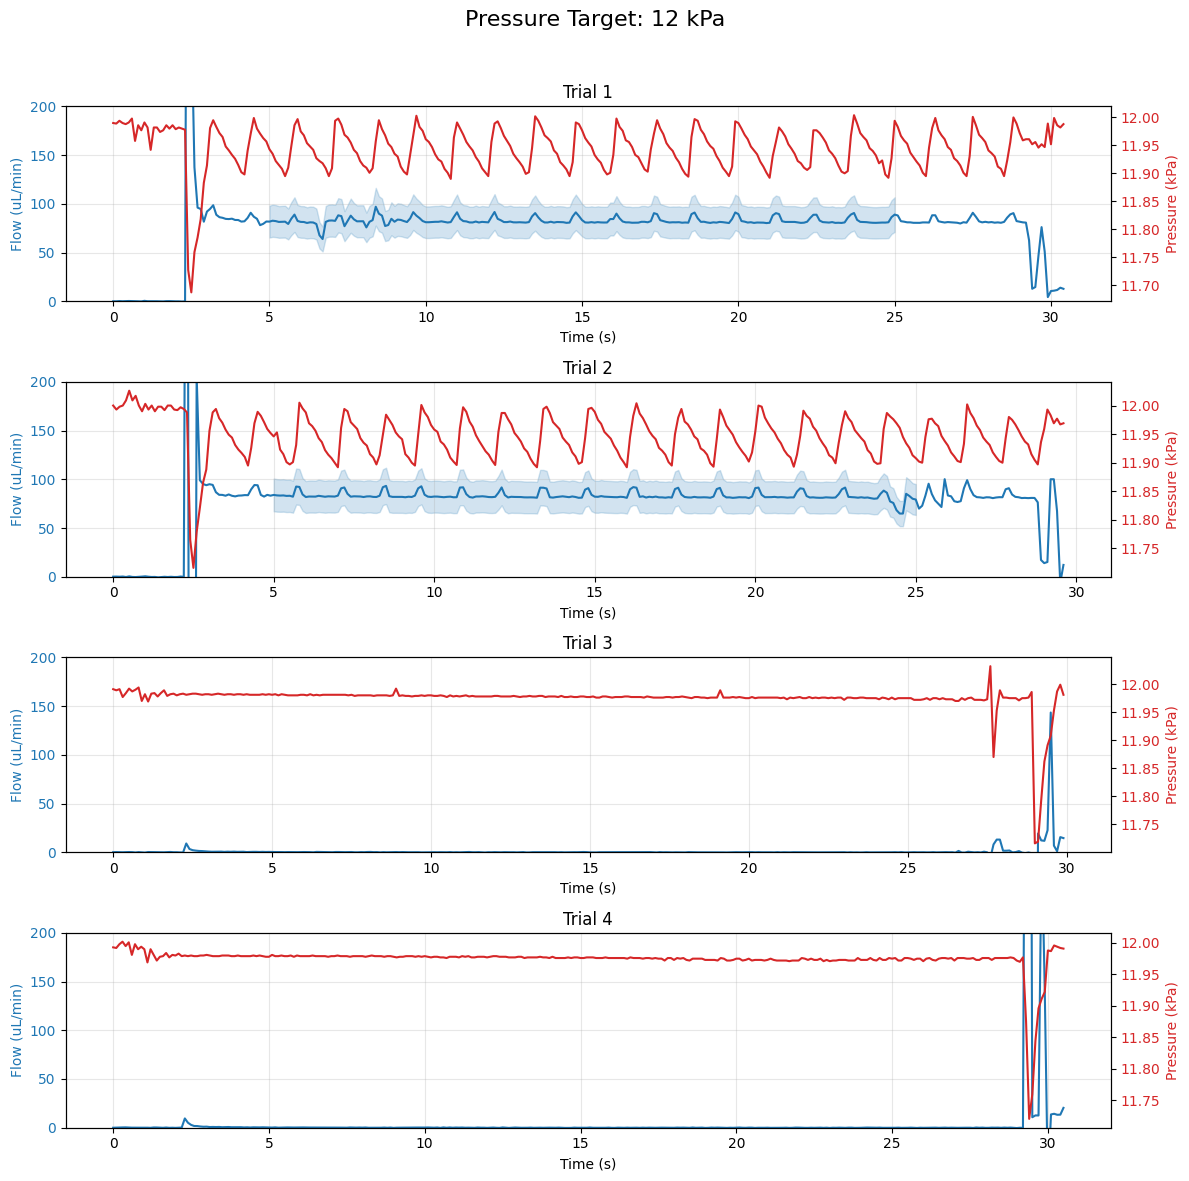

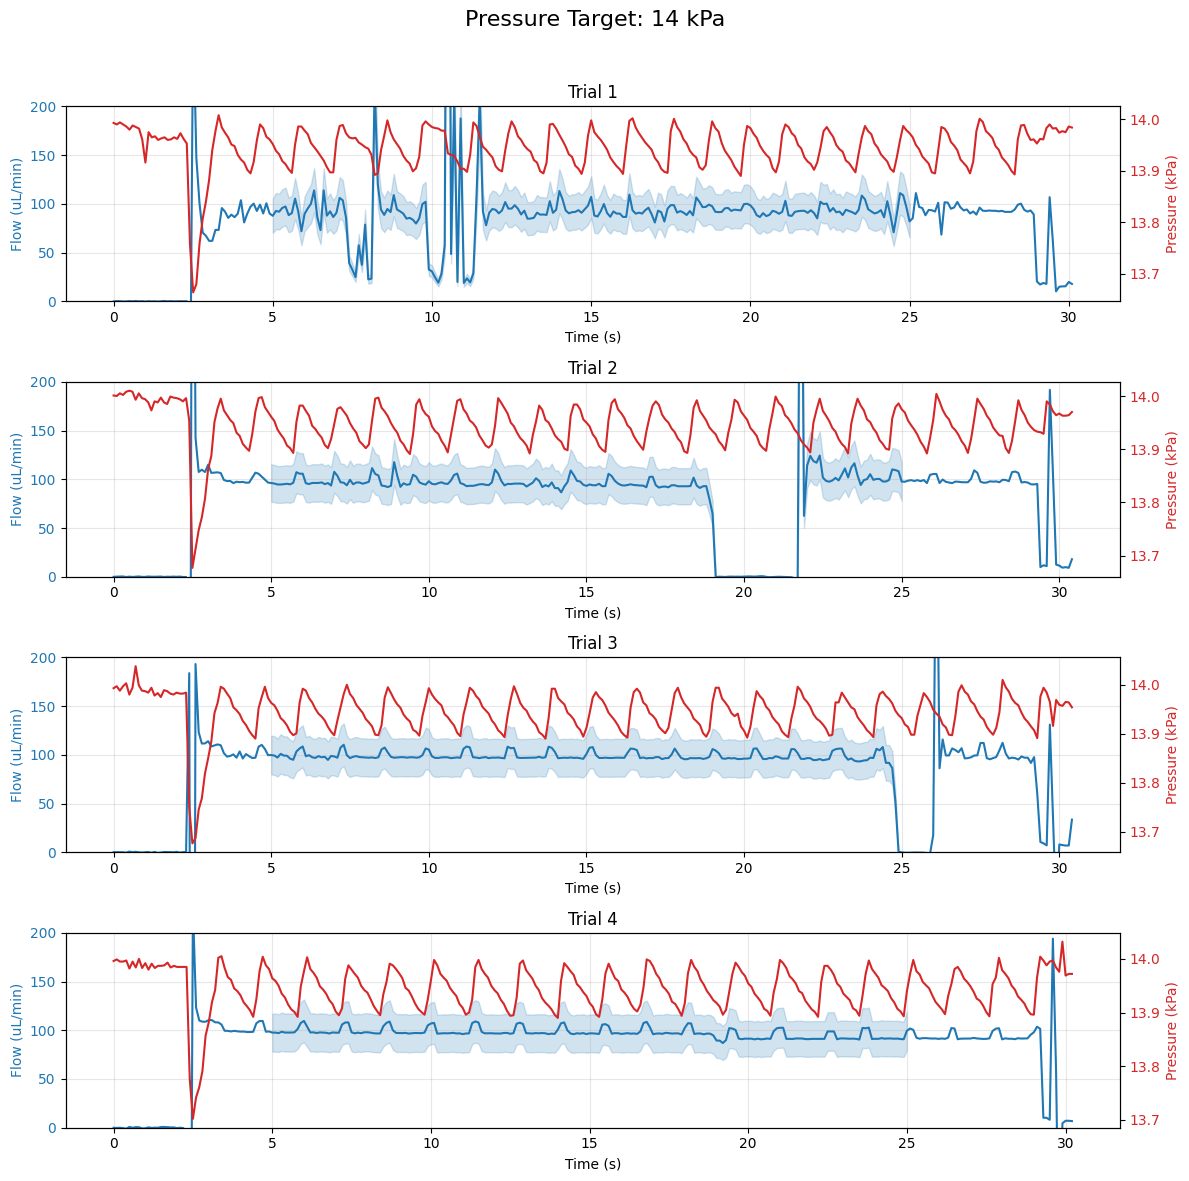

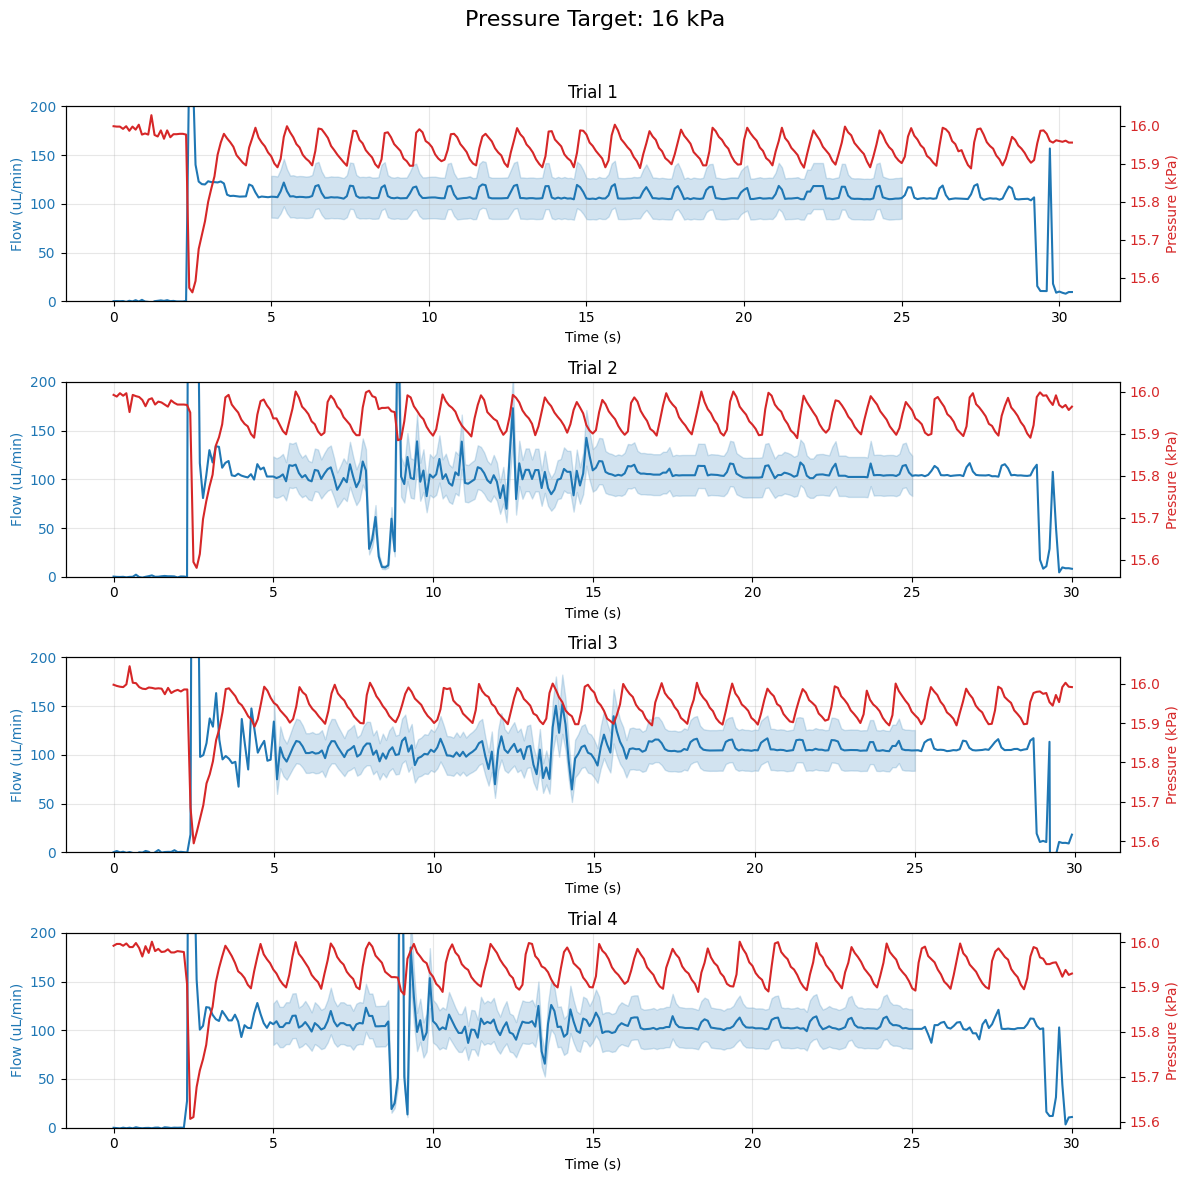

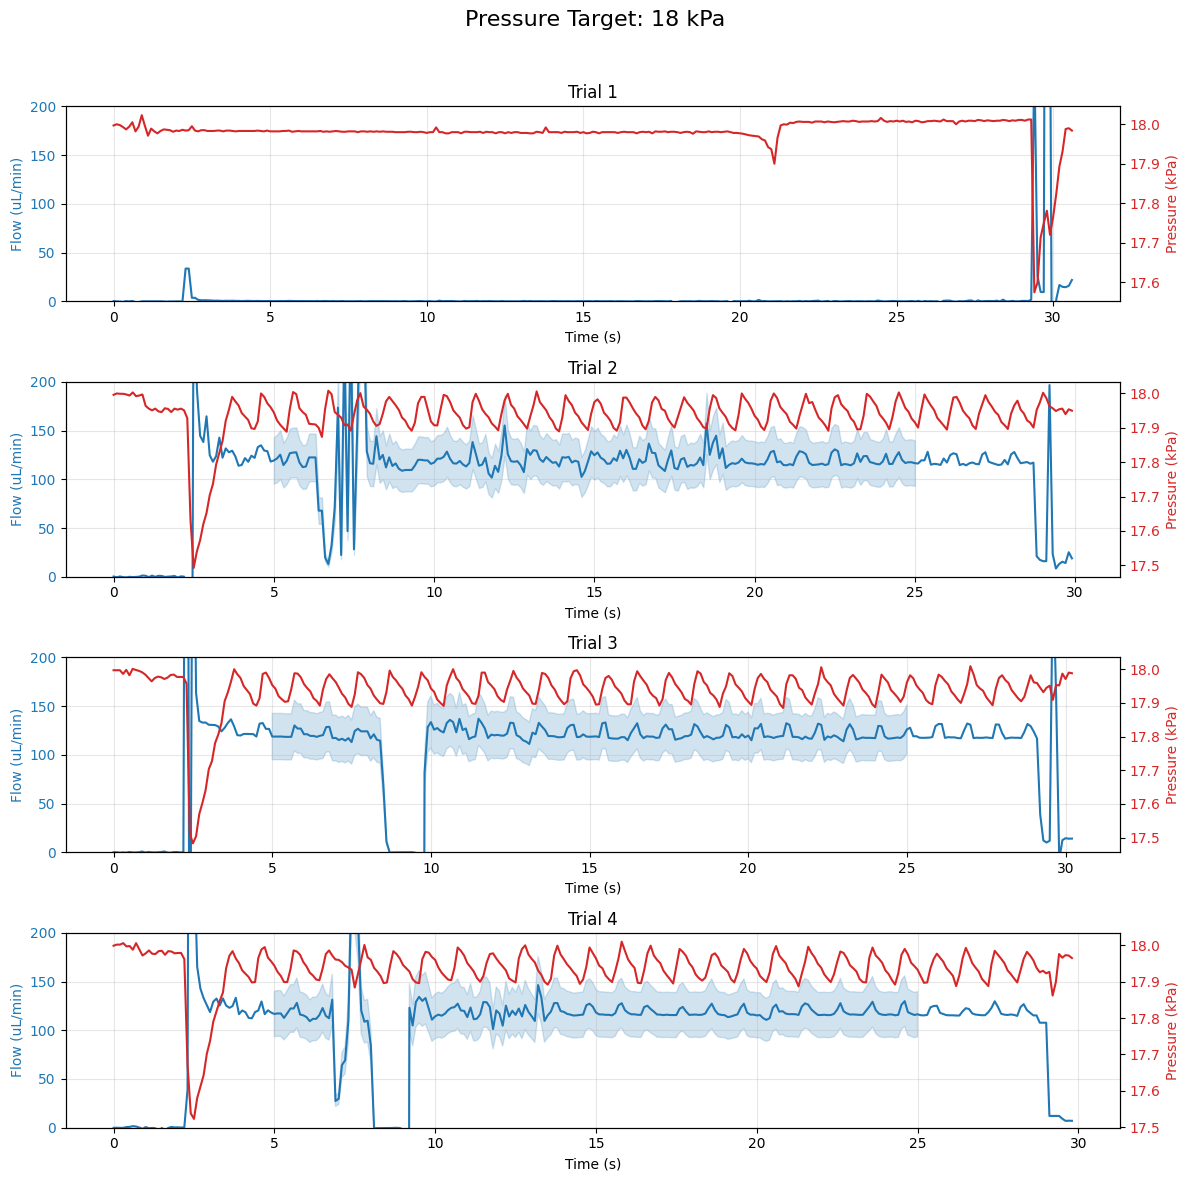

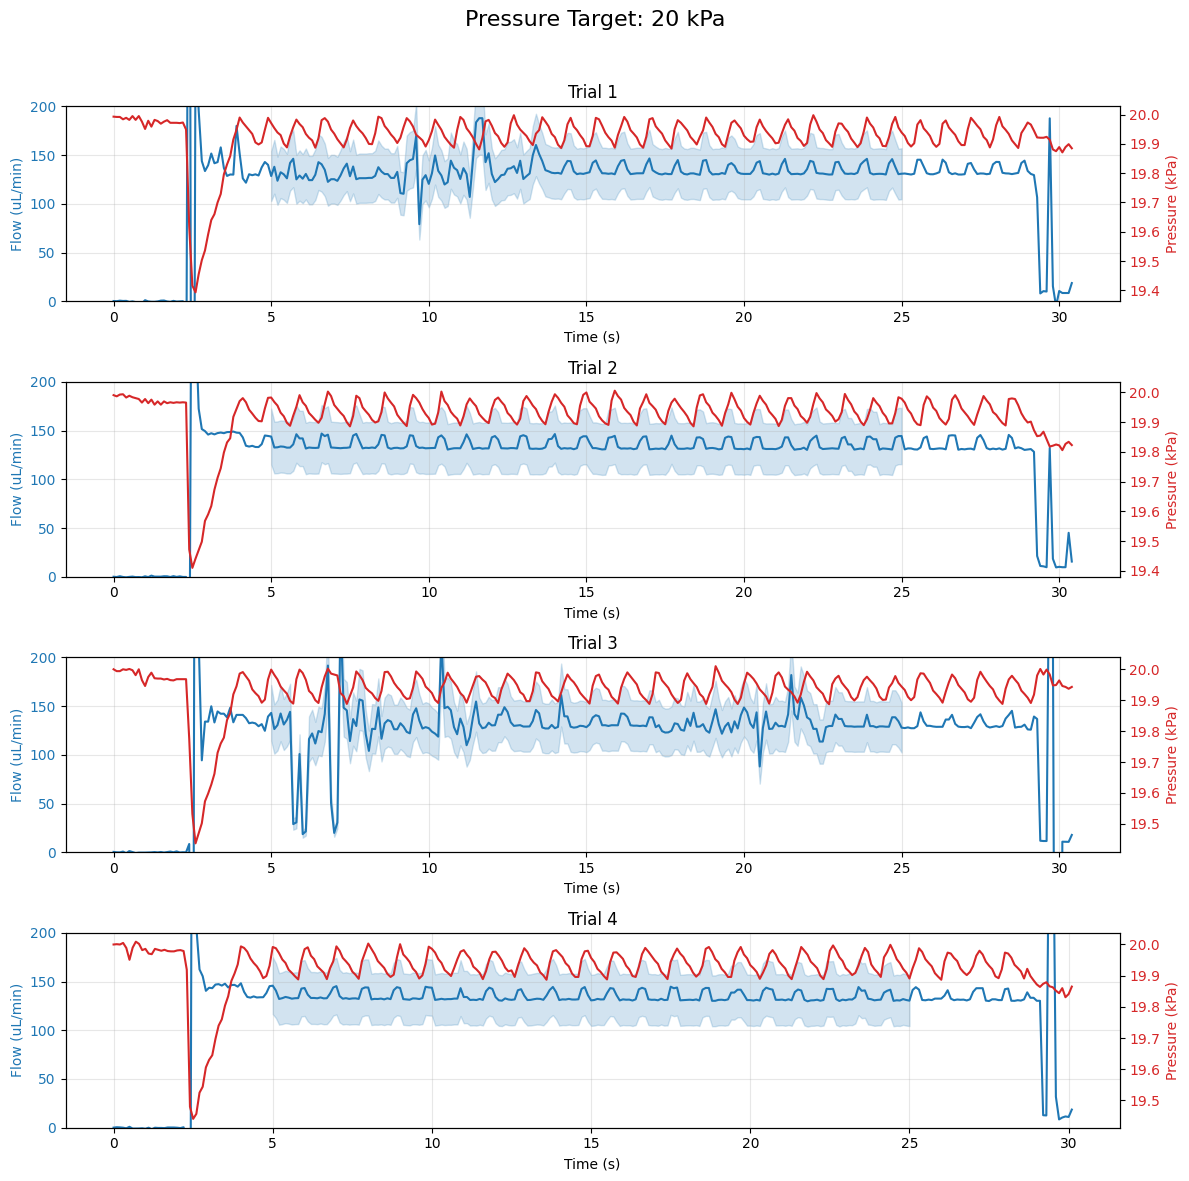

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt

base_path = "/Users/kylenp/Desktop/LabSmith/ReactionChamberChip_Calibration"

pressures = range(2, 22, 2)
n_trials = 4
sample_rate = 10

highlight_start, highlight_end = 5, 25
highlight_width = 0.2

for p in pressures:
    plt.figure(figsize=(12, 3 * n_trials))
    plt.suptitle(f"Pressure Target: {p} kPa", fontsize=16)

    for i in range(1, n_trials + 1):
        file_path = os.path.join(base_path, f"calib_{p}kpa_trial{i}.csv")

        try:
            df = pd.read_csv(file_path, sep=";", skiprows=[0])
            df.columns = df.columns.str.strip()

            flow_col = [c for c in df.columns if "SF06" in c][0]
            pressure_col = [c for c in df.columns if "Pressure" in c or "kPa" in c][0]

            flow = df[flow_col]
            pressure = df[pressure_col]
            time = df.index / sample_rate

            ax = plt.subplot(n_trials, 1, i)

            ax.plot(time, flow, color="tab:blue")
            ax.set_ylabel("Flow (uL/min)", color="tab:blue")
            ax.tick_params(axis='y', labelcolor="tab:blue")
            ax.set_ylim(0, 200)

            mask = (time >= highlight_start) & (time <= highlight_end)
            band = flow[mask].abs() * highlight_width
            ax.fill_between(time[mask], flow[mask]-band, flow[mask]+band,
                            color="tab:blue", alpha=0.2)

            ax2 = ax.twinx()
            ax2.plot(time, pressure, color="tab:red")
            ax2.set_ylabel("Pressure (kPa)", color="tab:red")
            ax2.tick_params(axis='y', labelcolor="tab:red")

            ax.set_title(f"Trial {i}")
            ax.set_xlabel("Time (s)")
            ax.grid(True, alpha=0.3)

        except Exception as e:
            print(f" {file_path}: {e}")

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()
